In [5]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [6]:
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv(r"C:\Users\MUKTADIR NISHAT\Downloads\hospital_data_unclean.csv")
df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,NaN,30.0,M,B-,CANCER,2024.01.31,Matthew Smith ##,"Sons and Miller,,",Blue Cross,18856.281305978155 USD,328.0,Urgent,02/02/2024,Paracetamol,N
1,LEsliE tErrY,62.0,M,A+,OBESITY,2019.08.20,Samantha Davies ##,"Kim Inc,,",Medicare,33643.327286577885 USD,265.0,Emergency,26-08-2019,Ibuprofen,unknown
2,dAnnY SMiTH,76.0,FEMALE,A-,OBESITY,09/22/2022,NaN,"Cook PLC,,",Aetna,27955.096078842456 USD,205.0,Emergency,07-10-2022,Aspirin,N
3,NaN,28.0,FEMALE,O+,DIABETES,11/18/2020,Kevin Wells ##,"Hernandez Rogers and Vang,,,",Medicare,37909.78240987528 USD,450.0,Elective,2020.12.18,Ibuprofen,abn
4,ADRIeNNe bELL,43.0,FEMALE,AB+-,CANCER,2022.09.19,Kathleen Hanna ##,NaN,NaN,14238.317813937623 USD,458.0,Urgent,10/09/2022,Penicillin,abn


In [7]:
df.columns

Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='str')

In [8]:
df.shape

(55505, 15)

In [9]:
df.dtypes

Name                      str
Age                   float64
Gender                    str
Blood Type                str
Medical Condition         str
Date of Admission         str
Doctor                    str
Hospital                  str
Insurance Provider        str
Billing Amount            str
Room Number           float64
Admission Type            str
Discharge Date            str
Medication                str
Test Results              str
dtype: object

In [10]:
df.describe()

,Age,Room Number
count,51065.000000,51064.000000
mean,51.576207,301.074554
std,19.591399,115.264773
min,13.000000,101.000000
25%,35.000000,202.000000
50%,52.000000,302.000000
75%,68.000000,400.000000
max,89.000000,500.000000


In [11]:
df.isnull().sum()

Name                  4440
Age                   4440
Gender                4440
Blood Type            4440
Medical Condition     4440
Date of Admission     4440
Doctor                4440
Hospital              4441
Insurance Provider    4442
Billing Amount        4440
Room Number           4441
Admission Type        4440
Discharge Date        4441
Medication            4440
Test Results          4440
dtype: int64

In [12]:
df['Name'] = (df['Name'].astype(str).str.strip().str.title()
    .replace({'Nan': 'Unknown', 'None': 'Unknown'})
)

df['Gender'] = df['Gender'].replace({'M': 'Male', 'F': 'Female', 'FEMALE': 'Female'})
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

df['Doctor'] = df['Doctor'].astype(str).str.replace('#', '', regex=False).str.strip().replace({'nan': 'Unknown'})
df['Hospital'] = df['Hospital'].astype(str).str.replace(',', '', regex=False).str.strip().replace({'nan': 'Unknown'})
df['Insurance Provider'] = (
    df['Insurance Provider'].astype(str)
    .str.replace('UnitedHealthcare', 'United Healthcare', regex=False)
    .str.strip().replace({'nan': 'Unknown'})
)

display(df[['Name', 'Gender', 'Doctor', 'Hospital', 'Insurance Provider']].head())
print("\nInsurance Providers:", df['Insurance Provider'].unique())

,Name,Gender,Doctor,Hospital,Insurance Provider
0,NaN,Male,Matthew Smith,Sons and Miller,Blue Cross
1,Leslie Terry,Male,Samantha Davies,Kim Inc,Medicare
2,Danny Smith,Female,NaN,Cook PLC,Aetna
3,NaN,Female,Kevin Wells,Hernandez Rogers and Vang,Medicare
4,Adrienne Bell,Female,Kathleen Hanna,NaN,NaN



Insurance Providers: <StringArray>
['Blue Cross', 'Medicare', 'Aetna', nan, 'United Healthcare', 'Cigna']
Length: 6, dtype: str


In [13]:
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Blood Type'] = (
    df['Blood Type'].fillna(df['Blood Type'].mode()[0])
    .astype(str).str.strip().str.upper()
    .str.replace(r'[+-]+', lambda m: m.group(0)[0], regex=True)
)

for col in ['Medical Condition', 'Medication', 'Admission Type']:
    df[col] = df[col].fillna('Unknown')

df['Room Number'] = df['Room Number'].fillna('Not Assign')

print("Blood Type Counts:\n", df['Blood Type'].value_counts())
print("\nNull Check:\n", df[['Age', 'Blood Type', 'Medical Condition', 'Medication', 'Admission Type', 'Room Number']].isna().sum())

Blood Type Counts:
 Blood Type
A-     10868
B-      6438
A+      6403
AB+     6385
B+      6380
AB-     6377
O+      6348
O-      6306
Name: count, dtype: int64

Null Check:
 Age                  0
Blood Type           0
Medical Condition    0
Medication           0
Admission Type       0
Room Number          0
dtype: int64


In [14]:
df['Billing Amount'] = df['Billing Amount'].astype(str).str.replace(' USD', '', regex=False).str.strip()
df['Billing Amount'] = pd.to_numeric(df['Billing Amount'], errors='coerce')
df['Billing Amount'] = df['Billing Amount'].fillna(df['Billing Amount'].mean()).round(2)

display(df[['Billing Amount']].head())
print("\nBilling Summary:\n", df['Billing Amount'].describe().round(2))

,Billing Amount
0,18856.28
1,33643.33
2,27955.10
3,37909.78
4,14238.32



Billing Summary:
 count    55505.00
mean     25553.79
std      13630.96
min      -2008.49
25%      14303.66
50%      25553.79
75%      36683.92
max      52764.28
Name: Billing Amount, dtype: float64


In [15]:
def parse_mixed_dates(series: pd.Series) -> pd.Series:
    s = series.astype(str).str.strip().str.replace('.', '-', regex=False).str.replace('/', '-', regex=False)
    parsed = pd.to_datetime(s, errors='coerce')
    mask = parsed.isna()
    parsed[mask] = pd.to_datetime(s[mask], errors='coerce', dayfirst=True)
    return parsed.fillna(parsed.median())

df['Date of Admission'] = parse_mixed_dates(df['Date of Admission'])
df['Discharge Date'] = parse_mixed_dates(df['Discharge Date'])

display(df[['Date of Admission', 'Discharge Date']].head())

,Date of Admission,Discharge Date
0,2024-01-31,2024-02-02
1,2019-08-20,2019-08-26
2,2022-09-22,2022-07-10
3,2020-11-18,2021-11-16
4,2022-09-19,2022-10-09


In [16]:
df['Stay_Days'] = (df['Discharge Date'] - df['Date of Admission']).dt.days
df['Admission_Year'] = df['Date of Admission'].dt.year
df['Admission_Month'] = df['Date of Admission'].dt.month

print("Total Remaining Null Values:", df.isna().sum().sum())
display(df.head())

Total Remaining Null Values: 22203


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Stay_Days,Admission_Year,Admission_Month
0,NaN,30.0,Male,B-,CANCER,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,328.0,Urgent,2024-02-02,Paracetamol,N,2,2024,1
1,Leslie Terry,62.0,Male,A+,OBESITY,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,265.0,Emergency,2019-08-26,Ibuprofen,unknown,6,2019,8
2,Danny Smith,76.0,Female,A-,OBESITY,2022-09-22,NaN,Cook PLC,Aetna,27955.10,205.0,Emergency,2022-07-10,Aspirin,N,-74,2022,9
3,NaN,28.0,Female,O+,DIABETES,2020-11-18,Kevin Wells,Hernandez Rogers and Vang,Medicare,37909.78,450.0,Elective,2021-11-16,Ibuprofen,abn,363,2020,11
4,Adrienne Bell,43.0,Female,AB+,CANCER,2022-09-19,Kathleen Hanna,NaN,NaN,14238.32,458.0,Urgent,2022-10-09,Penicillin,abn,20,2022,9


In [17]:
#(Medical Conditions)
condition_summary = (
    df[df['Medical Condition'] != 'Unknown']
    .groupby('Medical Condition')
    .agg(
        Total_Patients=('Name', 'count'),
        Avg_Age=('Age', 'mean'),
        Mean_Billing=('Billing Amount', 'mean'),
        Median_Billing=('Billing Amount', 'median')
    )
    .round(2)
    .sort_values(by='Mean_Billing', ascending=False)
)
print("Summary by Medical Condition")
display(condition_summary)




Summary by Medical Condition


,Total_Patients,Avg_Age,Mean_Billing,Median_Billing
Medical Condition,,,,
OBESITY,7836,51.41,25743.04,25553.79
ASTHMA,7784,51.53,25711.24,25553.79
DIABETES,7897,51.49,25590.50,25553.79
HYPERTENSION,7824,51.71,25560.55,25553.79
ARTHRITIS,7892,51.72,25502.60,25553.79
CANCER,7740,51.75,25102.19,25553.79


In [18]:
insurance_summary = (df[df['Insurance Provider'] != 'Unknown']
    .groupby('Insurance Provider')['Billing Amount']
    .agg(Claims_Count='count', Total_Billing='sum', Avg_Billing='mean')
    .round(2)
    .sort_values(by='Total_Billing', ascending=False)
)
print("Summary by Insurance Provider")
display(insurance_summary)

Summary by Insurance Provider


,Claims_Count,Total_Billing,Avg_Billing
Insurance Provider,,,
Cigna,10361,2.646263e+08,25540.61
Medicare,10241,2.626276e+08,25644.72
Blue Cross,10192,2.618924e+08,25695.88
United Healthcare,10247,2.594920e+08,25323.70
Aetna,10022,2.560190e+08,25545.70


In [19]:
print("Admission Type vs Test Results")
display(pd.crosstab(df[df['Admission Type'] != 'Unknown']['Admission Type'],
    df[df['Test Results'] != 'Unknown']['Test Results'],
    margins=True
))

Admission Type vs Test Results


Test Results,N,abn,unknown,All
Admission Type,,,,
Elective,5292,5385,5147,15824
Emergency,5165,5187,5146,15498
Urgent,5198,5233,5219,15650
All,15655,15805,15512,46972


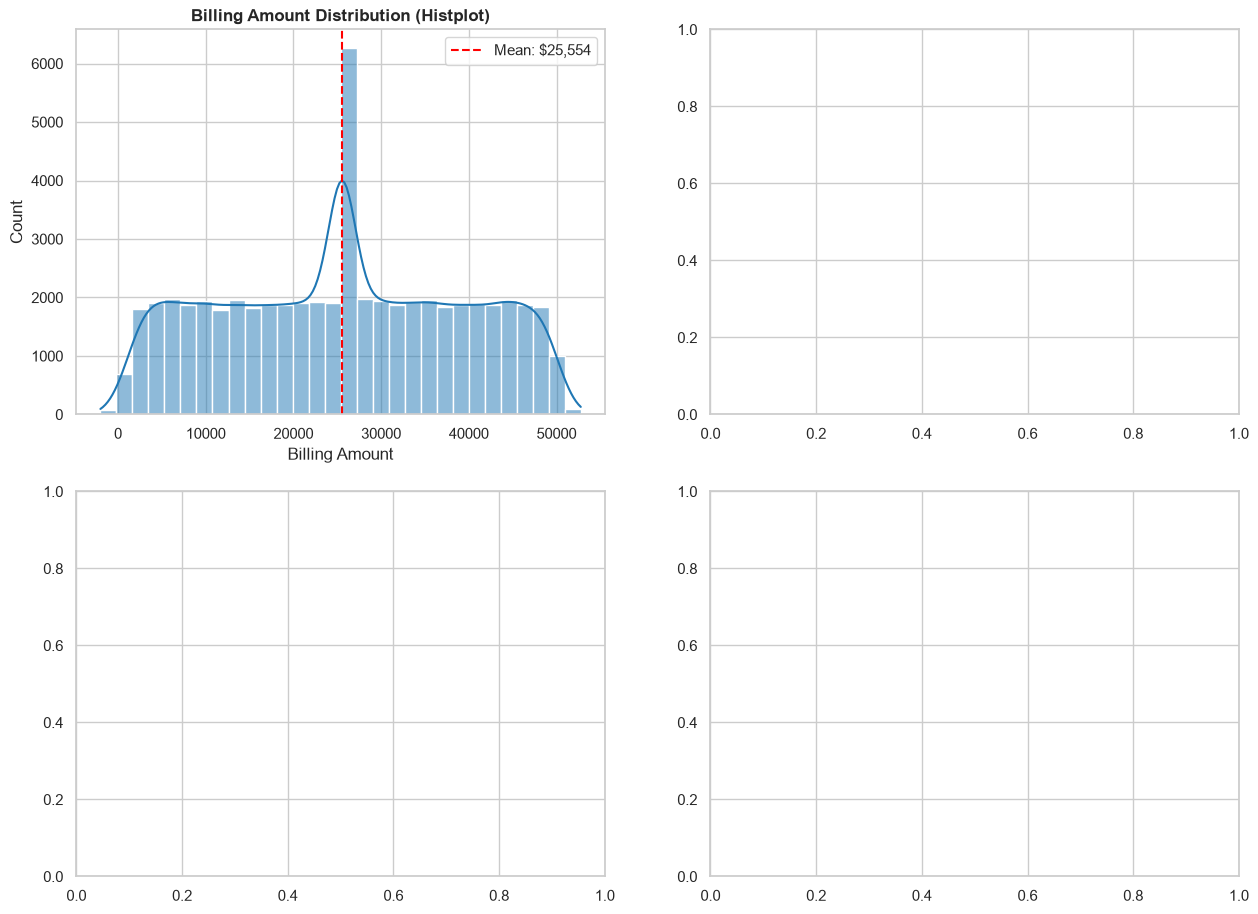

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# ১. Histplot: Billing Amount Distribution
sns.histplot(df['Billing Amount'], bins=30, kde=True, color='#1f77b4', ax=axes[0, 0])
axes[0, 0].axvline(df['Billing Amount'].mean(), color='red', linestyle='--', label=f"Mean: ${df['Billing Amount'].mean():,.0f}")
axes[0, 0].set_title('Billing Amount Distribution (Histplot)', fontweight='bold')
axes[0, 0].legend()

In [21]:
# Boxplot: Billing Amount by Medical Condition & Gender
sns.boxplot(
    data=df[df['Medical Condition'] != 'Unknown'],
    x='Medical Condition',
    y='Billing Amount',
    hue='Gender',
    palette='Set2',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Billing by Medical Condition & Gender (Boxplot)', fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=15)

In [22]:
#Correlation Heatmap
corr_cols = df[['Age', 'Billing Amount', 'Stay_Days', 'Admission_Year', 'Admission_Month']]
sns.heatmap(corr_cols.corr(), annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1, ax=axes[1, 0])
axes[1, 0].set_title('Numerical Features Correlation Heatmap', fontweight='bold')

Text(0.5, 1.0, 'Numerical Features Correlation Heatmap')

In [23]:
#Countplot: Admission Type vs Test Results
sns.countplot(
    data=df[(df['Admission Type'] != 'Unknown') & (df['Test Results'] != 'Unknown')],
    x='Admission Type',
    hue='Test Results',
    palette='viridis',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Admission Type vs Test Results', fontweight='bold')

plt.tight_layout()
plt.savefig('eda_dashboard.png', dpi=300)
plt.show()

<Figure size 640x480 with 0 Axes>

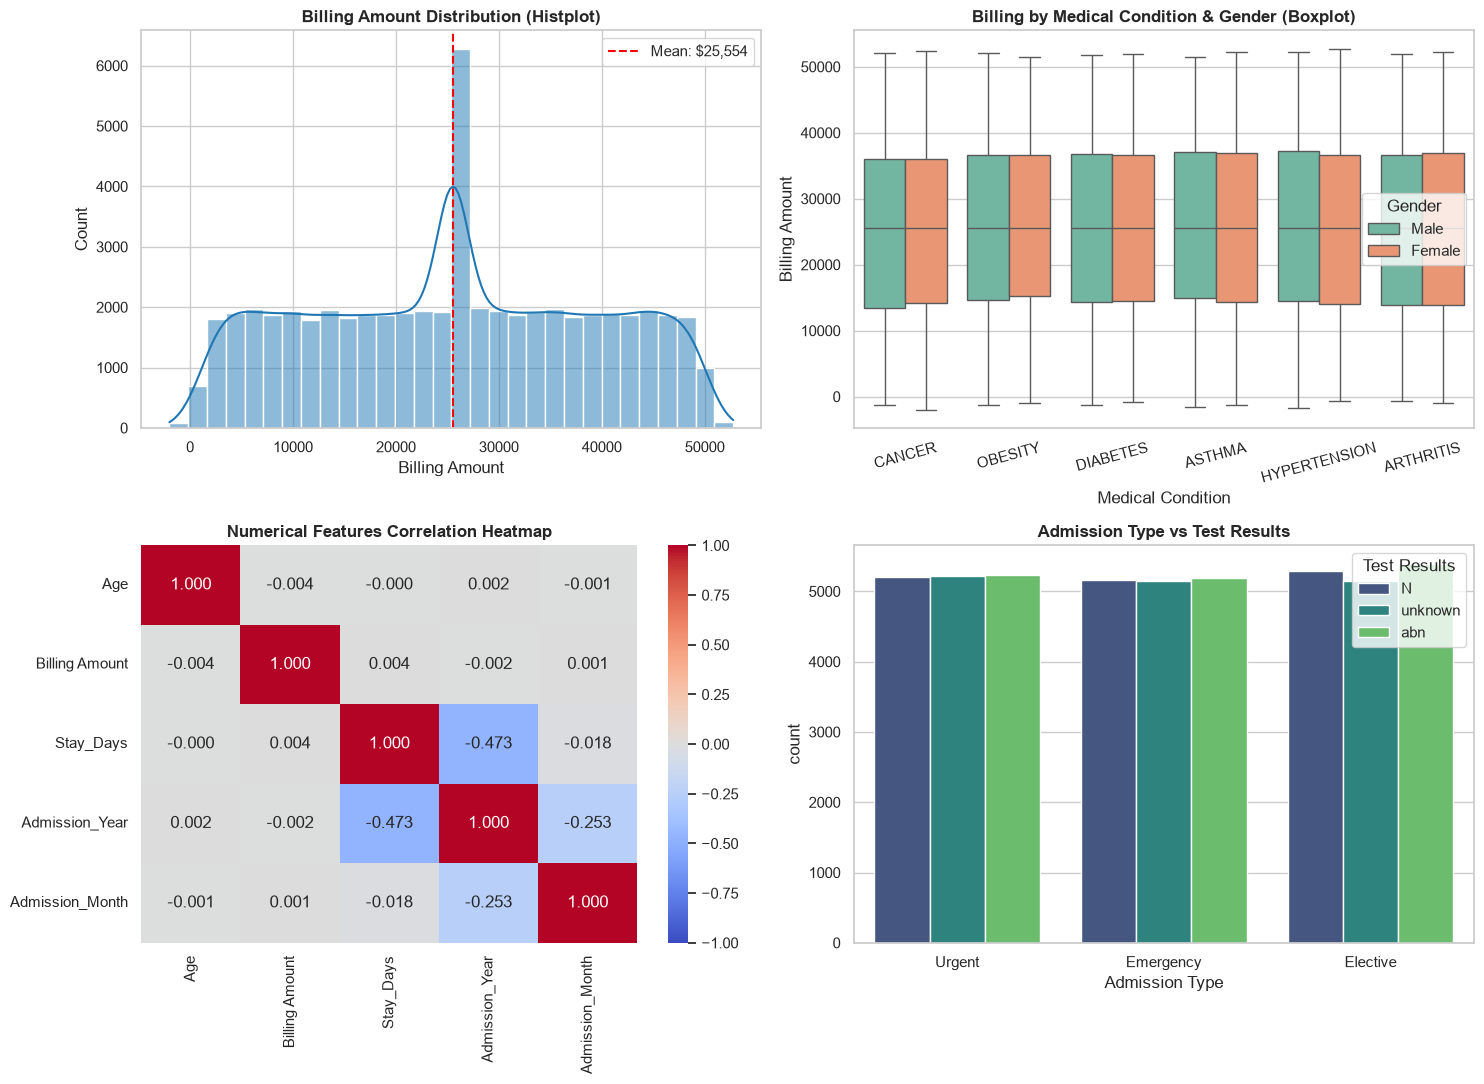

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

#Histplot: Billing Amount Distribution
sns.histplot(df['Billing Amount'], bins=30, kde=True, color='#1f77b4', ax=axes[0, 0])
axes[0, 0].axvline(df['Billing Amount'].mean(), color='red', linestyle='--', label=f"Mean: ${df['Billing Amount'].mean():,.0f}")
axes[0, 0].set_title('Billing Amount Distribution (Histplot)', fontweight='bold')
axes[0, 0].legend()

#Boxplot: Billing Amount by Medical Condition & Gender
sns.boxplot(
    data=df[df['Medical Condition'] != 'Unknown'],
    x='Medical Condition',
    y='Billing Amount',
    hue='Gender',
    palette='Set2',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Billing by Medical Condition & Gender (Boxplot)', fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=15)

#Correlation Heatmap
corr_cols = df[['Age', 'Billing Amount', 'Stay_Days', 'Admission_Year', 'Admission_Month']]
sns.heatmap(corr_cols.corr(), annot=True, cmap='coolwarm', fmt='.3f', vmin=-1, vmax=1, ax=axes[1, 0])
axes[1, 0].set_title('Numerical Features Correlation Heatmap', fontweight='bold')

#Countplot: Admission Type vs Test Results
sns.countplot(
    data=df[(df['Admission Type'] != 'Unknown') & (df['Test Results'] != 'Unknown')],
    x='Admission Type',
    hue='Test Results',
    palette='viridis',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Admission Type vs Test Results', fontweight='bold')

plt.tight_layout()
plt.savefig('eda_dashboard.png', dpi=300)
plt.show()

In [25]:
from scipy import stats


alpha = 0.05

# Test 1: Independent T-Test (Male vs Female Billing Amount)
male_bill = df[df['Gender'] == 'Male']['Billing Amount']
female_bill = df[df['Gender'] == 'Female']['Billing Amount']
t_stat, p_val_t = stats.ttest_ind(male_bill, female_bill, equal_var=False)

print(f"1. T-Test (Male vs Female Billing): t = {t_stat:.4f}, p-value = {p_val_t:.4f}")
print("   Result:", "Reject H0 (Significant difference)" if p_val_t < alpha else "Fail to Reject H0 (No significant difference)\n")

# Test 2: One-Way ANOVA (Billing Amount across Medical Conditions)
known_cond = df[df['Medical Condition'] != 'Unknown']
groups = [grp['Billing Amount'].values for _, grp in known_cond.groupby('Medical Condition')]
f_stat, p_val_anova = stats.f_oneway(*groups)

print(f"2. ANOVA (Billing across Medical Conditions): F = {f_stat:.4f}, p-value = {p_val_anova:.4f}")
print("   Result:", "Reject H0 (At least one condition differs)" if p_val_anova < alpha else "Fail to Reject H0 (No significant difference)\n")

# Test 3: Chi-Square Test (Admission Type vs Test Results)
known_cat = df[(df['Admission Type'] != 'Unknown') & (df['Test Results'] != 'Unknown')]
contingency_table = pd.crosstab(known_cat['Admission Type'], known_cat['Test Results'])
chi2_stat, p_val_chi2, dof, _ = stats.chi2_contingency(contingency_table)

print(f"3. Chi-Square (Admission Type vs Test Results): chi2 = {chi2_stat:.4f}, p-value = {p_val_chi2:.4f}")
print("   Result:", "Reject H0 (Variables are dependent)" if p_val_chi2 < alpha else "Fail to Reject H0 (Variables are independent)")

1. T-Test (Male vs Female Billing): t = 0.9581, p-value = 0.3380
   Result: Fail to Reject H0 (No significant difference)

2. ANOVA (Billing across Medical Conditions): F = 2.4197, p-value = 0.0335
   Result: Reject H0 (At least one condition differs)
3. Chi-Square (Admission Type vs Test Results): chi2 = 3.0021, p-value = 0.5575
   Result: Fail to Reject H0 (Variables are independent)


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [32]:
df_ml = pd.read_csv(r"C:\Users\MUKTADIR NISHAT\Downloads\hospital_data_unclean.csv")
df_ml.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,NaN,30.0,M,B-,CANCER,2024.01.31,Matthew Smith ##,"Sons and Miller,,",Blue Cross,18856.281305978155 USD,328.0,Urgent,02/02/2024,Paracetamol,N
1,LEsliE tErrY,62.0,M,A+,OBESITY,2019.08.20,Samantha Davies ##,"Kim Inc,,",Medicare,33643.327286577885 USD,265.0,Emergency,26-08-2019,Ibuprofen,unknown
2,dAnnY SMiTH,76.0,FEMALE,A-,OBESITY,09/22/2022,NaN,"Cook PLC,,",Aetna,27955.096078842456 USD,205.0,Emergency,07-10-2022,Aspirin,N
3,NaN,28.0,FEMALE,O+,DIABETES,11/18/2020,Kevin Wells ##,"Hernandez Rogers and Vang,,,",Medicare,37909.78240987528 USD,450.0,Elective,2020.12.18,Ibuprofen,abn
4,ADRIeNNe bELL,43.0,FEMALE,AB+-,CANCER,2022.09.19,Kathleen Hanna ##,NaN,NaN,14238.317813937623 USD,458.0,Urgent,10/09/2022,Penicillin,abn


In [ ]:
df_ml['Gender'] = df_ml['Gender'].replace({'M': 'Male', 'F': 'Female', 'FEMALE': 'Female'})
df_ml['Gender'] = df_ml['Gender'].fillna(df_ml['Gender'].mode()[0])

df_ml['Age'] = pd.to_numeric(df_ml['Age'], errors='coerce')
df_ml['Age'] = df_ml['Age'].fillna(df_ml['Age'].mean())

df_ml['Blood Type'] = (
    df_ml['Blood Type'].fillna(df_ml['Blood Type'].mode()[0])
    .astype(str).str.strip().str.upper()
    .str.replace(r'[+-]+', lambda m: m.group(0)[0], regex=True)
)

df_ml['Insurance Provider'] = (
    df_ml['Insurance Provider'].astype(str)
    .str.replace('UnitedHealthcare', 'United Healthcare', regex=False)
    .str.strip().replace({'nan': 'Unknown', 'None': 'Unknown'})
)

for col in ['Medical Condition', 'Medication', 'Admission Type']:
    df_ml[col] = df_ml[col].fillna('Unknown').astype(str).str.strip()

df_ml['Billing Amount'] = pd.to_numeric(
    df_ml['Billing Amount'].astype(str).str.replace(' USD', '', regex=False).str.strip(),
    errors='coerce'
)
df_ml['Billing Amount'] = df_ml['Billing Amount'].fillna(df_ml['Billing Amount'].mean()).round(2)

df_ml['Test Results'] = (
    df_ml['Test Results'].fillna('Unknown').astype(str).str.strip()
    .replace({'unknown': 'Unknown', 'abn': 'Abnormal', 'ABN': 'Abnormal', 'N': 'Normal'})
)


def safe_parse_dates(series: pd.Series) -> pd.Series:
    s = series.astype(str).str.strip().str.replace('.', '-', regex=False).str.replace('/', '-', regex=False)
    parsed = pd.to_datetime(s, errors='coerce')
    mask = parsed.isna()
    parsed[mask] = pd.to_datetime(s[mask], errors='coerce', dayfirst=True)
    return parsed.fillna(parsed.median())

df_ml['Date of Admission'] = safe_parse_dates(df_ml['Date of Admission'])
df_ml['Discharge Date'] = safe_parse_dates(df_ml['Discharge Date'])
df_ml['Stay_Days'] = (df_ml['Discharge Date'] - df_ml['Date of Admission']).dt.days
df_ml['Admission_Month'] = df_ml['Date of Admission'].dt.month

print("Step 3 Done: Dataset cleaned! Shape:", df_ml.shape)

Step 3 Done: Dataset cleaned! Shape: (55505, 17)


In [34]:
ml_data = df_ml[df_ml['Test Results'].isin(['Normal', 'Abnormal'])].copy()
ml_data['Target'] = ml_data['Test Results'].map({'Normal': 0, 'Abnormal': 1}).astype(int)

num_features = ['Age', 'Billing Amount', 'Stay_Days', 'Admission_Month']
cat_features = ['Gender', 'Blood Type', 'Medical Condition', 'Insurance Provider', 'Admission Type', 'Medication']

for c in num_features:
    ml_data[c] = pd.to_numeric(ml_data[c], errors='coerce').fillna(0.0).astype(float)

for c in cat_features:
    ml_data[c] = ml_data[c].astype(str)

X = ml_data[num_features + cat_features]
y = ml_data['Target']

print("Step 4 Done: Features & Target ready!")
print("X shape:", X.shape)
print("\nTarget Counts:\n", y.value_counts())

Step 4 Done: Features & Target ready!
X shape: (34162, 10)

Target Counts:
 Target
1    17123
0    17039
Name: count, dtype: int64


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Step 5 Done: Data Split Complete!")
print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

Step 5 Done: Data Split Complete!
Training rows: 27329
Testing rows:  6833


In [36]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ]
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

model_pipeline.fit(X_train, y_train)
print("Step 6 Done: Random Forest Model Trained Successfully!")

Step 6 Done: Random Forest Model Trained Successfully!


In [37]:
y_pred = model_pipeline.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Step 7 Done: Model Test Accuracy = {acc:.4f} ({acc*100:.2f}%)\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Abnormal (1)']))

Step 7 Done: Model Test Accuracy = 0.5116 (51.16%)

--- Classification Report ---
              precision    recall  f1-score   support

  Normal (0)       0.51      0.47      0.49      3408
Abnormal (1)       0.51      0.55      0.53      3425

    accuracy                           0.51      6833
   macro avg       0.51      0.51      0.51      6833
weighted avg       0.51      0.51      0.51      6833



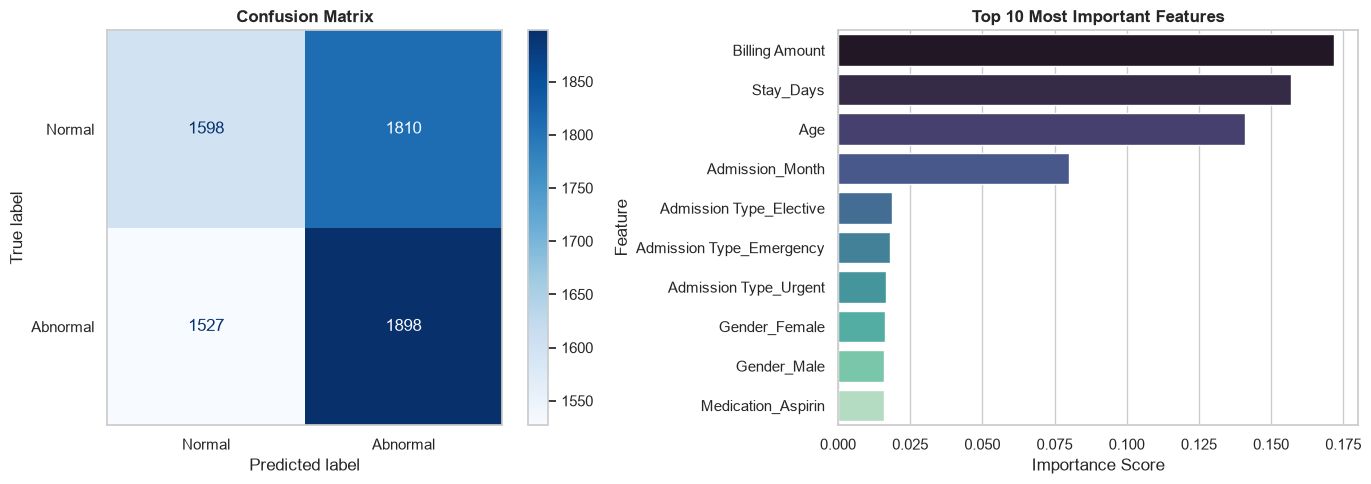

Step 8 Done: Chart saved as 'ml_evaluation.png'!


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Normal', 'Abnormal'],
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].grid(False)

# Feature Importance
ohe_step = model_pipeline.named_steps['preprocessor'].named_transformers_['cat']
ohe_names = list(ohe_step.get_feature_names_out(cat_features))
all_feature_names = num_features + ohe_names

importances = model_pipeline.named_steps['classifier'].feature_importances_
feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=False).head(10)

sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='mako', ax=axes[1])
axes[1].set_title('Top 10 Most Important Features', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importance Score')
axes[1].set_ylabel('Feature')

plt.tight_layout()
plt.savefig('ml_evaluation.png', dpi=300)
plt.show()
print("Step 8 Done: Chart saved as 'ml_evaluation.png'!")